Cell 1 – Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

from scipy.cluster.hierarchy import dendrogram, linkage

import warnings
warnings.filterwarnings('ignore')

Cell 2 – Upload and load dataset

In [2]:
from google.colab import files

uploaded = files.upload()

df = pd.read_csv('Mall_Customers.csv')

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


Cell 3 – Understand the dataset

In [3]:
print("Dataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB

Statistical Summary:


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000



Missing Values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Duplicate Rows:
0


Cell 4 – Data cleaning and feature selection

In [4]:
df = df.drop_duplicates()

features = df[['Annual Income (k$)',
               'Spending Score (1-100)']]

print(features.head())

   Annual Income (k$)  Spending Score (1-100)
0                  15                      39
1                  15                      81
2                  16                       6
3                  16                      77
4                  17                      40


Cell 5 – Exploratory Data Analysis

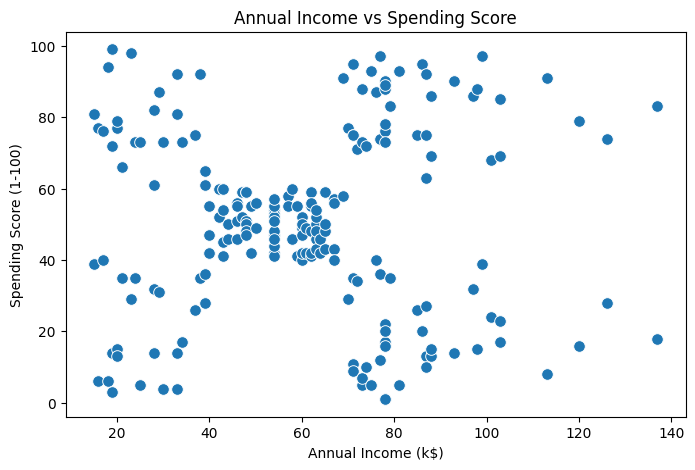

In [5]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    s=70
)

plt.title('Annual Income vs Spending Score')
plt.show()

Cell 6 – StandardScaler

In [6]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(features)

print("Standardized data:")
print(X_scaled[:5])

Standardized data:
[[-1.73899919 -0.43480148]
 [-1.73899919  1.19570407]
 [-1.70082976 -1.71591298]
 [-1.70082976  1.04041783]
 [-1.66266033 -0.39597992]]


Cell 7 – Build the dendrogram

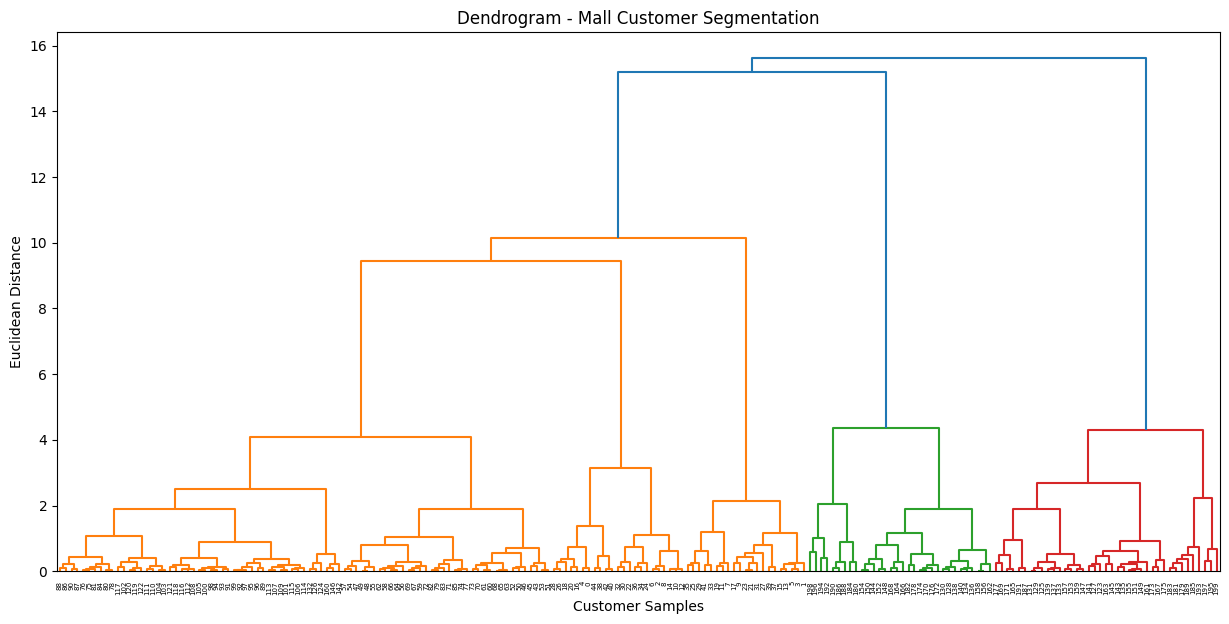

In [7]:
plt.figure(figsize=(15,7))

linked = linkage(X_scaled, method='ward')

dendrogram(
    linked,
    orientation='top',
    distance_sort='descending',
    show_leaf_counts=True
)

plt.title('Dendrogram - Mall Customer Segmentation')
plt.xlabel('Customer Samples')
plt.ylabel('Euclidean Distance')

plt.show()

Cell 8 – Build the clustering model

In [8]:
model = AgglomerativeClustering(
    n_clusters=5,
    linkage='ward'
)

df['Cluster'] = model.fit_predict(X_scaled)

print(df[['Annual Income (k$)',
          'Spending Score (1-100)',
          'Cluster']].head(10))

   Annual Income (k$)  Spending Score (1-100)  Cluster
0                  15                      39        4
1                  15                      81        3
2                  16                       6        4
3                  16                      77        3
4                  17                      40        4
5                  17                      76        3
6                  18                       6        4
7                  18                      94        3
8                  19                       3        4
9                  19                      72        3


Cell 9 – Evaluate the model

In [9]:
score = silhouette_score(X_scaled, df['Cluster'])

print("Silhouette Score:", round(score, 3))

print("\nCustomers in each cluster:")
print(df['Cluster'].value_counts().sort_index())

Silhouette Score: 0.554

Customers in each cluster:
Cluster
0    32
1    39
2    85
3    21
4    23
Name: count, dtype: int64


Cell 10 – Visualize customer segments

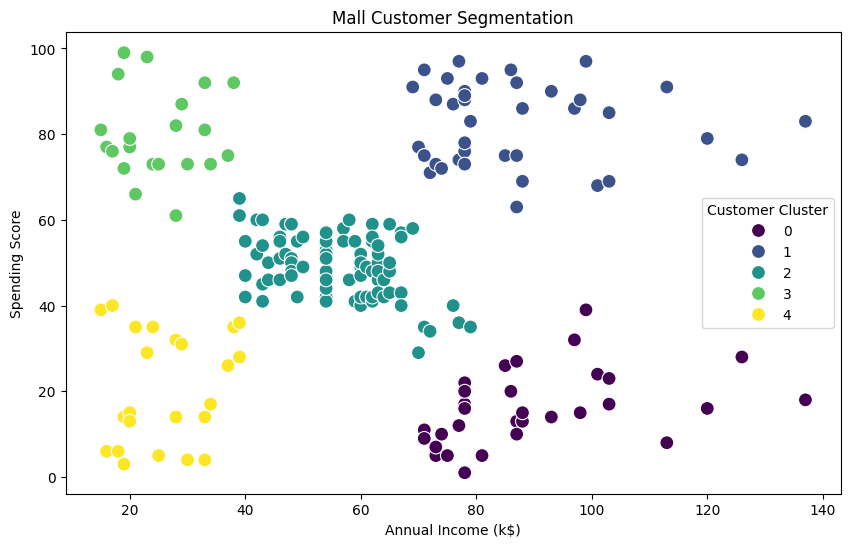

In [10]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=df,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue='Cluster',
    palette='viridis',
    s=100
)

plt.title('Mall Customer Segmentation')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score')
plt.legend(title='Customer Cluster')

plt.show()

Cell 11 – Understand the customer groups

In [11]:
cluster_summary = df.groupby('Cluster')[
    ['Annual Income (k$)', 'Spending Score (1-100)']
].mean().round(2)

display(cluster_summary)

,Annual Income (k$),Spending Score (1-100)
Cluster,,
0,89.41,15.59
1,86.54,82.13
2,55.81,49.13
3,25.10,80.05
4,26.30,20.91


In [14]:
from google.colab import auth
from google.colab import sheets

# Explicitly run the authentication flow
auth.authenticate_user()

sheet = sheets.InteractiveSheet(df=cluster_summary)

https://docs.google.com/spreadsheets/d/1jAgYLgZd62clVpi8REc-zIOhOEzrL8nABenh7zTCfxo/edit#gid=0


Cell 12 – Save the results

In [12]:
df.to_csv('Mall_Customer_Segmentation_Results.csv',
          index=False)

files.download('Mall_Customer_Segmentation_Results.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>